In [2]:
import requests

url = "https://apps.fs.usda.gov/ArcX/rest/services/EDW/EDW_InsectandDiseaseSurvey_01/MapServer/1/query"
params = {
    "where": "SURVEY_YEAR >= 2012 AND SURVEY_YEAR <= 2016",
    "geometry": "-119.5,35.5,-118.5,37.5",
    "geometryType": "esriGeometryEnvelope",
    "inSR": "4326",
    "spatialRel": "esriSpatialRelIntersects",
    "outFields": "*",
    "returnGeometry": "true",
    "f": "geojson",
}
r = requests.get(url, params=params)
print(r.status_code)
data = r.json()
print(list(data.get("features", [{}])[0].get("properties", {}).keys()) if data.get("features") else data)


200
{'type': 'FeatureCollection', 'features': []}


In [3]:
import requests

layer_info = requests.get(
    "https://apps.fs.usda.gov/ArcX/rest/services/EDW/EDW_InsectandDiseaseSurvey_01/MapServer/1",
    params={"f": "json"},
).json()

print([f["name"] for f in layer_info.get("fields", [])])


['objectid', 'damage_area_id', 'created_date', 'modified_date', 'feature_user_id', 'observation_user_id', 'region_id', 'label', 'host_code', 'host', 'host_group_code', 'host_group', 'dca_code', 'dca_common_name', 'damage_type_code', 'damage_type', 'percent_affected_code', 'percent_affected', 'percent_min', 'percent_max', 'percent_mid', 'notes', 'observation_count', 'collection_mode', 'snapgrid_row', 'snapgrid_column', 'area_type', 'acres', 'status', 'survey_year', 'legacy_severity_code', 'legacy_severity', 'legacy_pattern_code', 'legacy_pattern', 'legacy_tpa', 'legacy_no_trees', 'legacy_forest_type_code', 'legacy_forest_type', 'grp', 'observation_id', 'ids_data_source', 'data_source_name', 'us_area', 'shape', 'st_area(shape)', 'st_perimeter(shape)']


In [4]:
params = {
    "where": "1=1",
    "outFields": "survey_year",
    "returnGeometry": "false",
    "returnDistinctValues": "true",
    "f": "json",
}
r = requests.get(url, params=params)
data = r.json()
years = sorted(set(f["attributes"]["survey_year"] for f in data.get("features", [])))
print(years)


[2021, 2022, 2023, 2024, 2025]


In [5]:
import requests

features = []
offset = 0
page_size = 2000
url = "https://services2.arcgis.com/Uq9r85Potqm3MfRV/ArcGIS/rest/services/biosds2783_fpu/FeatureServer/0/query"

while True:
    params = {
        "where": "RPT_YR >= 2012 AND RPT_YR <= 2016",
        "geometry": "-119.5,35.5,-118.5,37.5",
        "geometryType": "esriGeometryEnvelope",
        "inSR": "4326",
        "spatialRel": "esriSpatialRelIntersects",
        "outFields": "*",
        "f": "geojson",
        "resultRecordCount": page_size,
        "resultOffset": offset,
    }
    r = requests.get(url, params=params)
    batch = r.json().get("features", [])
    features.extend(batch)
    if len(batch) < page_size:
        break
    offset += page_size

print(len(features))
print(features[0]["properties"] if features else "no features")


9916
{'OBJECTID': 154299, 'RPT_YR': 2012, 'SURVEY_ID1': 'FHP', 'SURVEY_ID2': '-1', 'SURVEY_ID3': '-1', 'DMG_TYPE1': 'Mortality', 'DMG_TYPE2': 'No Data', 'DMG_TYPE3': 'No Data', 'SEVERITY1': 'No data', 'SEVERITY2': 'No data', 'SEVERITY3': 'No data', 'PATTERN1': None, 'PATTERN2': None, 'PATTERN3': None, 'TPA1': 1.43989100205, 'TPA2': -1, 'TPA3': -1, 'TPA_Total': 1.439891, 'NO_TREES1': 1, 'NO_TREES2': 0, 'NO_TREES3': 0, 'NO_TREES_TOTAL': 1, 'DCA1': 'western pine beetle', 'DCA2': 'No Data', 'DCA3': 'No Data', 'HOST1': 'ponderosa pine', 'HOST2': None, 'HOST3': None, 'FOR_TYPE1': 'Ponderosa pine', 'FOR_TYPE2': None, 'FOR_TYPE3': None, 'ACRES': 0.6945000237707799, 'NOTES': '1!pp', 'no_years': 1, 'Date': None, 'ADS_ID': None, 'Shape__Length0': None, 'Shape__Area0': None, 'Shape__Area': 4425.82421875, 'Shape__Length': 236.08801287078455}


In [6]:
from collections import Counter
print(Counter(f["properties"].get("DCA1") for f in features).most_common(15))


[('western pine beetle', 3027), ('mountain pine beetle', 2513), ('fir engraver', 1785), ('drought', 1103), ('Jeffery pine beetle', 924), ('California flathead borer', 142), ('Multi-Damage (Insect/Disease)', 117), ('Cytospora canker of fir', 70), ('Unknown', 69), ('Bark Beetles', 64), ('winter injury', 48), ('Fire', 31), ('Ips engraver beetles', 11), ('pinon ips', 6), ('satin moth', 2)]


In [7]:
import geopandas as gpd
from shapely.geometry import shape

TPA_CAP = 80.0  # UC Cooperative Extension: 20-80 dead trees/acre in severe Sierra mortality areas

def compute_severity_weight(p):
    tpa = p.get("TPA_Total")
    if tpa is None:
        acres = p.get("ACRES")
        trees = p.get("NO_TREES_TOTAL")
        if acres and trees and acres > 0:
            tpa = trees / acres
        else:
            tpa = 0.0
    return min(max(tpa, 0), TPA_CAP) / TPA_CAP

rows = []
for f in features:
    p = f["properties"]
    rows.append({
        "geometry": shape(f["geometry"]),
        "RPT_YR": p["RPT_YR"],
        "ACRES": p["ACRES"],
        "TPA_Total": p["TPA_Total"],
        "severity_weight": compute_severity_weight(p),
    })

ads_gdf = gpd.GeoDataFrame(rows, crs="EPSG:4326")
ads_gdf["damaged_acres"] = ads_gdf["ACRES"] * ads_gdf["severity_weight"]
print(len(ads_gdf), ads_gdf["damaged_acres"].sum())
print(ads_gdf["TPA_Total"].isna().sum(), "features had missing TPA_Total")


9916 543052.0314060146
191 features had missing TPA_Total


In [8]:
rows = []
for f in features:
    p = f["properties"]
    rows.append({
        "geometry": shape(f["geometry"]),
        "RPT_YR": p["RPT_YR"],
        "ACRES": p["ACRES"],
        "TPA_Total": p["TPA_Total"],
        "HOST1": p.get("HOST1"),
        "FOR_TYPE1": p.get("FOR_TYPE1"),
        "severity_weight": compute_severity_weight(p),
    })

ads_gdf = gpd.GeoDataFrame(rows, crs="EPSG:4326")
ads_gdf["damaged_acres"] = ads_gdf["ACRES"] * ads_gdf["severity_weight"]

print(ads_gdf["HOST1"].value_counts())


HOST1
ponderosa pine           2686
Jeffrey pine              930
lodgepole pine            789
sugar pine                709
white fir                 688
California red fir        597
blue oak                  430
whitebark pine            320
fir                       219
interior live oak         163
western white pine         81
softwoods *                33
oak(deciduous)             24
canyon live oak            19
grey pine                  16
limber pine                16
California black oak       16
pine                       13
hardwoods/softwoods *      12
hardwoods *                10
quaking aspen               6
singleleaf pinyon           5
bigleaf maple               3
cottonwood, poplar          2
not listed                  2
knobcone pine               2
incense-cedar               2
eucalyptus                  1
foxtail pine                1
willow                      1
California sycamore         1
Name: count, dtype: int64


In [9]:
import xarray as xr
import numpy as np

spei_ds = xr.open_dataset("../data/raw/spei12.nc")
lats = spei_ds["lat"].values
lons = spei_ds["lon"].values

# SPEI cells whose centers fall in/near the pilot bbox
bbox = dict(lon=slice(-119.5, -118.5), lat=slice(35.5, 37.5))
pilot_lats = spei_ds.sel(**bbox)["lat"].values
pilot_lons = spei_ds.sel(**bbox)["lon"].values
print(pilot_lats, pilot_lons)  # check how many cells we actually have to work with

def nearest_cell(lon, lat):
    lat_i = pilot_lats[np.argmin(np.abs(pilot_lats - lat))]
    lon_i = pilot_lons[np.argmin(np.abs(pilot_lons - lon))]
    return (lat_i, lon_i)

ads_proj = ads_gdf.to_crs(3310)
centroids_latlon = ads_proj.centroid.to_crs(4326)

ads_gdf["cell"] = [
    nearest_cell(pt.x, pt.y) for pt in centroids_latlon
]
damaged_by_cell = ads_gdf.groupby("cell")["damaged_acres"].sum()
print(damaged_by_cell)


[35.75 36.25 36.75 37.25] [-119.25 -118.75]
cell
(35.75, -119.25)         0.312500
(35.75, -118.75)     77372.902371
(36.25, -119.25)        10.070879
(36.25, -118.75)    119043.467886
(36.75, -119.25)     44842.682255
(36.75, -118.75)     80968.158974
(37.25, -119.25)    217841.254377
(37.25, -118.75)      2973.182165
Name: damaged_acres, dtype: float64


In [10]:
import ee
ee.Authenticate()
ee.Initialize(project="tree-fire-510209")


In [11]:
import ee
import pandas as pd
ee.Initialize()

nlcd = ee.ImageCollection("USGS/NLCD_RELEASES/2016_REL").filter(ee.Filter.eq("system:index", "2016")).first()
forest_mask = nlcd.select("landcover").remap([41, 42, 43], [1, 1, 1], 0)
pixel_area_acres = ee.Image.pixelArea().divide(4046.8564224)
forested_acres_img = forest_mask.multiply(pixel_area_acres).rename("forested_acres")

forested_by_cell = {}
for lat, lon in damaged_by_cell.index:
    geom = ee.Geometry.Rectangle([lon - 0.25, lat - 0.25, lon + 0.25, lat + 0.25])
    val = forested_acres_img.reduceRegion(ee.Reducer.sum(), geom, scale=30, maxPixels=1e9).get("forested_acres")
    forested_by_cell[(lat, lon)] = val.getInfo()

forested_by_cell = pd.Series(forested_by_cell)
print(forested_by_cell)


/home/jupyter/climate_impact_curves/.venv/lib/python3.12/site-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for USGS/NLCD_RELEASES/2016_REL! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by USGS/NLCD_RELEASES/2019_REL/NLCD

Learn more: https://developers.google.com/earth-engine/datasets/catalog/USGS_NLCD_RELEASES_2016_REL

  warnings.warn(warning, category=DeprecationWarning)


35.75  -119.25         0.000000
       -118.75    123851.546960
36.25  -119.25       103.901127
       -118.75    274671.031010
36.75  -119.25    123273.302924
       -118.75    304203.119595
37.25  -119.25    422221.289933
       -118.75    143857.351558
dtype: float64


In [12]:
loss_share = damaged_by_cell / forested_by_cell
loss_share = loss_share.where(forested_by_cell > 0)  # avoid div-by-zero; NaN for near-empty cells
loss_share = loss_share.clip(0, 1)
print(loss_share.sort_values(ascending=False))


cell
(35.75, -118.75)    0.624723
(37.25, -119.25)    0.515941
(36.25, -118.75)    0.433404
(36.75, -119.25)    0.363766
(36.75, -118.75)    0.266165
(36.25, -119.25)    0.096928
(37.25, -118.75)    0.020668
(35.75, -119.25)         NaN
dtype: float64


In [13]:
spei_by_cell = {}
for lat, lon in loss_share.index:
    val = (
        spei_ds["spei"]
        .sel(lat=lat, lon=lon, method="nearest")
        .sel(time=slice("2012-01-01", "2016-12-31"))
        .mean()
    )
    spei_by_cell[(lat, lon)] = float(val)

spei_by_cell = pd.Series(spei_by_cell)

curve_df = pd.DataFrame({"loss_share": loss_share, "spei": spei_by_cell}).dropna()
print(curve_df.sort_values("spei"))


                  loss_share      spei
(36.25, -119.25)    0.096928 -0.957353
(36.25, -118.75)    0.433404 -0.856199
(36.75, -118.75)    0.266165 -0.792466
(37.25, -119.25)    0.515941 -0.722372
(37.25, -118.75)    0.020668 -0.701279
(36.75, -119.25)    0.363766 -0.636741
(35.75, -118.75)    0.624723 -0.452709


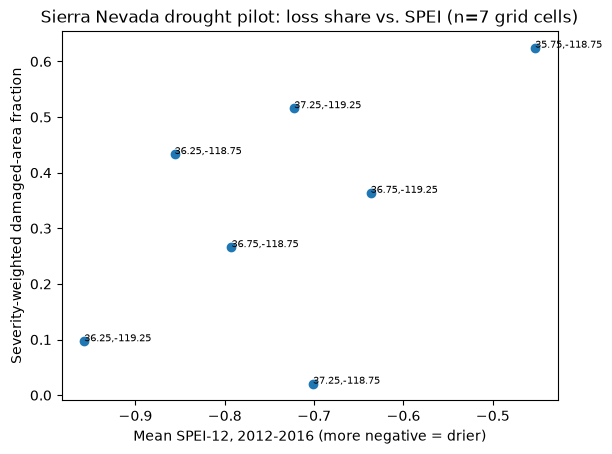

In [14]:
import matplotlib.pyplot as plt

plt.scatter(curve_df["spei"], curve_df["loss_share"])
for (lat, lon), row in curve_df.iterrows():
    plt.annotate(f"{lat},{lon}", (row["spei"], row["loss_share"]), fontsize=7)
plt.xlabel("Mean SPEI-12, 2012-2016 (more negative = drier)")
plt.ylabel("Severity-weighted damaged-area fraction")
plt.title("Sierra Nevada drought pilot: loss share vs. SPEI (n=7 grid cells)")
plt.savefig("../data/raw/drought_loss_vs_spei.png")
plt.show()


In [15]:
cell_a = ads_gdf[ads_gdf["cell"] == (37.25, -119.25)]  # loss_share 0.52
cell_b = ads_gdf[ads_gdf["cell"] == (37.25, -118.75)]  # loss_share 0.02

print("=== (37.25, -119.25), high loss share ===")
print(cell_a["HOST1"].value_counts())
print("damaged acres by species:")
print(cell_a.groupby("HOST1")["damaged_acres"].sum().sort_values(ascending=False))

print("\n=== (37.25, -118.75), low loss share ===")
print(cell_b["HOST1"].value_counts())
print("damaged acres by species:")
print(cell_b.groupby("HOST1")["damaged_acres"].sum().sort_values(ascending=False))


=== (37.25, -119.25), high loss share ===
HOST1
ponderosa pine           1060
lodgepole pine            276
Jeffrey pine              238
white fir                 221
California red fir        154
sugar pine                129
fir                        80
whitebark pine             26
western white pine         25
blue oak                   12
interior live oak          12
pine                        3
hardwoods/softwoods *       2
grey pine                   2
oak(deciduous)              2
softwoods *                 1
Name: count, dtype: int64
damaged acres by species:
HOST1
ponderosa pine           107100.291697
white fir                 59368.860591
fir                       19238.327947
Jeffrey pine              15383.338718
California red fir        10471.111450
lodgepole pine             4922.766410
sugar pine                  318.188585
interior live oak           191.840189
blue oak                    151.584249
whitebark pine               68.749993
oak(deciduous)          

In [16]:
rows = []
for f in features:
    p = f["properties"]
    rows.append({
        "geometry": shape(f["geometry"]),
        "RPT_YR": p["RPT_YR"],
        "ACRES": p["ACRES"],
        "TPA_Total": p["TPA_Total"],
        "NO_TREES_TOTAL": p.get("NO_TREES_TOTAL"),
        "HOST1": p.get("HOST1"),
        "FOR_TYPE1": p.get("FOR_TYPE1"),
        "severity_weight": compute_severity_weight(p),
    })

ads_gdf = gpd.GeoDataFrame(rows, crs="EPSG:4326")
ads_gdf["damaged_acres"] = ads_gdf["ACRES"] * ads_gdf["severity_weight"]
ads_proj = ads_gdf.to_crs(3310)
centroids_latlon = ads_proj.centroid.to_crs(4326)
ads_gdf["cell"] = [nearest_cell(pt.x, pt.y) for pt in centroids_latlon]


In [17]:
ponderosa = ads_gdf[ads_gdf["HOST1"] == "ponderosa pine"]

ponderosa_by_cell = ponderosa.groupby("cell").agg(
    mean_tpa=("TPA_Total", "mean"),
    total_dead_trees=("NO_TREES_TOTAL", "sum"),
    total_damaged_acres=("damaged_acres", "sum"),
    n_polygons=("TPA_Total", "count"),
)
print(ponderosa_by_cell)


                   mean_tpa  total_dead_trees  total_damaged_acres  n_polygons
cell                                                                          
(35.75, -118.75)  23.257823           5285135         65343.741997         458
(36.25, -118.75)  21.981725           4072746         50378.525765         566
(36.75, -119.25)  24.730397           2154608         26562.369452         229
(36.75, -118.75)  26.348616           3247254         39457.549145         372
(37.25, -119.25)  25.935216           8614835        107100.291697        1060
(37.25, -118.75)   6.380949                10             0.125000           1


In [18]:
import requests

features_wide = []
offset = 0
page_size = 2000
url = "https://services2.arcgis.com/Uq9r85Potqm3MfRV/ArcGIS/rest/services/biosds2783_fpu/FeatureServer/0/query"

while True:
    params = {
        "where": "RPT_YR >= 2012 AND RPT_YR <= 2016",
        "geometry": "-121.0,35.0,-117.5,40.0",
        "geometryType": "esriGeometryEnvelope",
        "inSR": "4326",
        "spatialRel": "esriSpatialRelIntersects",
        "outFields": "*",
        "f": "geojson",
        "resultRecordCount": page_size,
        "resultOffset": offset,
    }
    r = requests.get(url, params=params)
    batch = r.json().get("features", [])
    features_wide.extend(batch)
    if len(batch) < page_size:
        break
    offset += page_size

print(len(features_wide))


49666


In [19]:
TPA_CAP = 80.0  # UC Cooperative Extension: 20-80 dead trees/acre in severe Sierra mortality areas

def compute_severity_weight(p):
    tpa = p.get("TPA_Total")
    if tpa is None:
        acres = p.get("ACRES")
        trees = p.get("NO_TREES_TOTAL")
        if acres and trees and acres > 0:
            tpa = trees / acres
        else:
            tpa = 0.0
    return min(max(tpa, 0), TPA_CAP) / TPA_CAP


In [20]:
import geopandas as gpd
from shapely.geometry import shape

rows_wide = []
for f in features_wide:
    p = f["properties"]
    rows_wide.append({
        "geometry": shape(f["geometry"]),
        "RPT_YR": p["RPT_YR"],
        "ACRES": p["ACRES"],
        "TPA_Total": p["TPA_Total"],
        "NO_TREES_TOTAL": p.get("NO_TREES_TOTAL"),
        "HOST1": p.get("HOST1"),
        "FOR_TYPE1": p.get("FOR_TYPE1"),
        "severity_weight": compute_severity_weight(p),
    })

ads_gdf_wide = gpd.GeoDataFrame(rows_wide, crs="EPSG:4326")
ads_gdf_wide["damaged_acres"] = ads_gdf_wide["ACRES"] * ads_gdf_wide["severity_weight"]

ads_proj_wide = ads_gdf_wide.to_crs(3310)
centroids_wide = ads_proj_wide.centroid.to_crs(4326)

print(len(ads_gdf_wide))
print(ads_gdf_wide["HOST1"].value_counts().head(10))


49666
HOST1
ponderosa pine        14211
white fir              5137
Jeffrey pine           4041
lodgepole pine         2813
singleleaf pinyon      1950
sugar pine             1919
California red fir     1854
whitebark pine         1611
grey pine              1265
fir                     886
Name: count, dtype: int64


In [21]:
import xarray as xr
import numpy as np

spei_ds = xr.open_dataset("../data/raw/spei12.nc")

wide_bbox = dict(lon=slice(-121.0, -117.5), lat=slice(35.0, 40.0))
wide_lats = spei_ds.sel(**wide_bbox)["lat"].values
wide_lons = spei_ds.sel(**wide_bbox)["lon"].values
print(len(wide_lats), len(wide_lons), wide_lats, wide_lons)

def nearest_cell_wide(lon, lat):
    lat_i = wide_lats[np.argmin(np.abs(wide_lats - lat))]
    lon_i = wide_lons[np.argmin(np.abs(wide_lons - lon))]
    return (lat_i, lon_i)

ads_gdf_wide["cell"] = [nearest_cell_wide(pt.x, pt.y) for pt in centroids_wide]
print(ads_gdf_wide["cell"].nunique(), "distinct grid cells touched")


10 7 [35.25 35.75 36.25 36.75 37.25 37.75 38.25 38.75 39.25 39.75] [-120.75 -120.25 -119.75 -119.25 -118.75 -118.25 -117.75]
52 distinct grid cells touched


In [22]:
ponderosa_wide = ads_gdf_wide[ads_gdf_wide["HOST1"] == "ponderosa pine"]

ponderosa_by_cell_wide = ponderosa_wide.groupby("cell").agg(
    mean_tpa=("TPA_Total", "mean"),
    n_polygons=("TPA_Total", "count"),
)
ponderosa_by_cell_wide = ponderosa_by_cell_wide[ponderosa_by_cell_wide["n_polygons"] >= 5]
print(len(ponderosa_by_cell_wide), "usable cells (n>=5 polygons)")

spei_by_cell_wide = {}
for lat, lon in ponderosa_by_cell_wide.index:
    val = (
        spei_ds["spei"]
        .sel(lat=lat, lon=lon, method="nearest")
        .sel(time=slice("2012-01-01", "2016-12-31"))
        .mean()
    )
    spei_by_cell_wide[(lat, lon)] = float(val)

import pandas as pd
spei_by_cell_wide = pd.Series(spei_by_cell_wide)

curve_df_wide = ponderosa_by_cell_wide.copy()
curve_df_wide["spei"] = curve_df_wide.index.map(spei_by_cell_wide)
curve_df_wide = curve_df_wide.dropna()
print(curve_df_wide.sort_values("spei"))


23 usable cells (n>=5 polygons)
                   mean_tpa  n_polygons      spei
cell                                             
(35.25, -118.75)  13.656901          87 -1.147117
(35.25, -118.25)   4.017979          20 -1.065040
(35.25, -120.25)   5.391511           5 -1.028493
(36.25, -118.75)  21.981725         566 -0.856199
(38.75, -119.75)   4.312479           6 -0.841310
(39.25, -120.75)   7.767531        1307 -0.795695
(36.75, -118.75)  26.348616         372 -0.792466
(38.75, -120.25)   5.372153         489 -0.784349
(35.75, -118.25)  10.534330          22 -0.784028
(37.75, -119.75)  17.447011         955 -0.783813
(38.75, -120.75)   7.757371        1878 -0.729659
(37.25, -119.25)  25.924862        1047 -0.722372
(36.25, -118.25)   4.183273          20 -0.713766
(38.25, -120.75)   9.620313        1062 -0.702595
(37.75, -120.25)  22.681586        1054 -0.688069
(39.75, -120.25)   3.023640         208 -0.685587
(37.25, -119.75)  21.948713        1183 -0.672116
(39.25, -120.25)  

corr(mean_tpa, spei): 0.21278796411657375
corr(mean_tpa, lat): -0.36594146873484956
corr(mean_tpa, lon): 0.32434862701992795


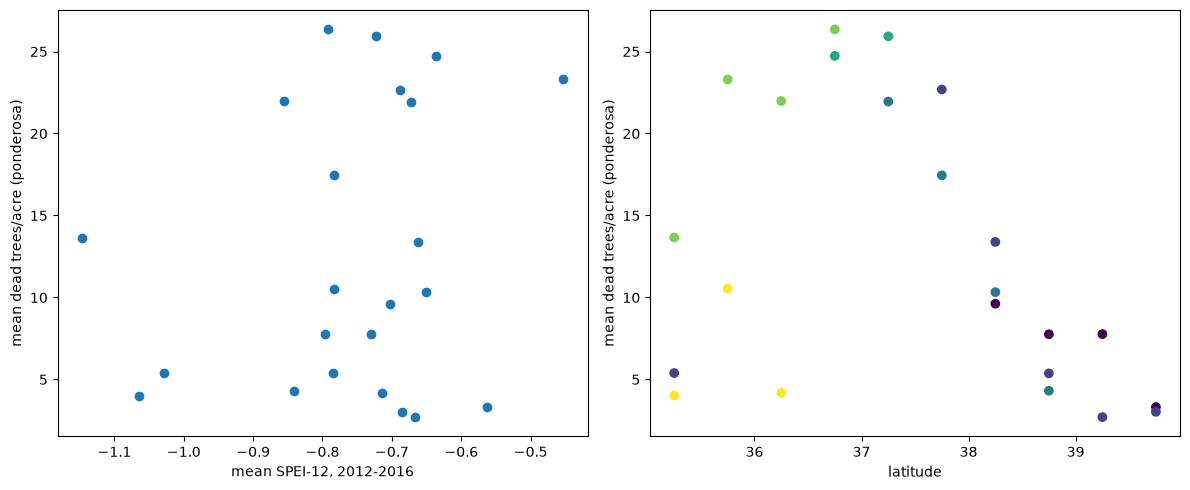

In [23]:
import numpy as np
import matplotlib.pyplot as plt

curve_df_wide["lat"] = [c[0] for c in curve_df_wide.index]
curve_df_wide["lon"] = [c[1] for c in curve_df_wide.index]

print("corr(mean_tpa, spei):", np.corrcoef(curve_df_wide["spei"], curve_df_wide["mean_tpa"])[0,1])
print("corr(mean_tpa, lat):", np.corrcoef(curve_df_wide["lat"], curve_df_wide["mean_tpa"])[0,1])
print("corr(mean_tpa, lon):", np.corrcoef(curve_df_wide["lon"], curve_df_wide["mean_tpa"])[0,1])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(curve_df_wide["spei"], curve_df_wide["mean_tpa"])
axes[0].set_xlabel("mean SPEI-12, 2012-2016")
axes[0].set_ylabel("mean dead trees/acre (ponderosa)")
axes[1].scatter(curve_df_wide["lat"], curve_df_wide["mean_tpa"], c=curve_df_wide["lon"], cmap="viridis")
axes[1].set_xlabel("latitude")
axes[1].set_ylabel("mean dead trees/acre (ponderosa)")
plt.tight_layout()
plt.savefig("../data/raw/drought_wide_diagnostics.png", dpi=150)
plt.show()


corr(residual, spei): 0.26273280919663267


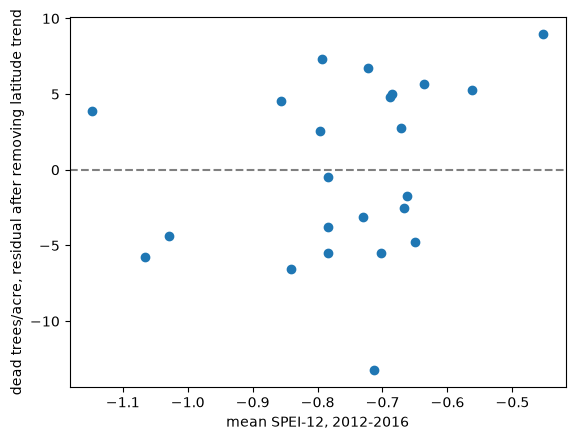

In [24]:
coeffs = np.polyfit(curve_df_wide["lat"], curve_df_wide["mean_tpa"], 2)
predicted = np.polyval(coeffs, curve_df_wide["lat"])
curve_df_wide["residual"] = curve_df_wide["mean_tpa"] - predicted

print("corr(residual, spei):", np.corrcoef(curve_df_wide["spei"], curve_df_wide["residual"])[0,1])

plt.scatter(curve_df_wide["spei"], curve_df_wide["residual"])
plt.xlabel("mean SPEI-12, 2012-2016")
plt.ylabel("dead trees/acre, residual after removing latitude trend")
plt.axhline(0, color="grey", linestyle="--")
plt.savefig("../data/raw/drought_residual_vs_spei.png", dpi=150)
plt.show()


In [25]:
import ee
ee.Initialize(project="tree-fire-510209")

dem = ee.Image("USGS/SRTMGL1_003").select("elevation")

def get_mean_elevation(geom):
    stats = dem.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=geom,
        scale=30,
        maxPixels=1e9
    )
    return stats.get("elevation").getInfo()


In [26]:
ads_ponderosa = ads_gdf[ads_gdf["HOST1"].str.contains("ponderosa", case=False, na=False)].copy()
print(len(ads_ponderosa))


2686


In [27]:
elevations = []
for geom in ads_ponderosa.geometry:
    ee_geom = ee.Geometry(geom.__geo_interface__)
    elevations.append(get_mean_elevation(ee_geom))

ads_ponderosa["elevation_m"] = elevations
print(ads_ponderosa[["elevation_m"]].describe())


       elevation_m
count  2681.000000
mean   1568.312329
std     354.503658
min     528.048365
25%    1313.553804
50%    1584.767381
75%    1816.338185
max    2730.197209


In [28]:
import ee

dem = ee.Image("USGS/SRTMGL1_003").select("elevation")
cell_half = 0.25  # half of the 0.5deg grid spacing

def get_cell_elevation(lat, lon):
    box = ee.Geometry.Rectangle([lon - cell_half, lat - cell_half,
                                   lon + cell_half, lat + cell_half])
    stats = dem.reduceRegion(reducer=ee.Reducer.mean(), geometry=box,
                              scale=90, maxPixels=1e9)
    return stats.get("elevation").getInfo()

curve_df_wide["elevation_m"] = [
    get_cell_elevation(lat, lon) for lat, lon in zip(curve_df_wide["lat"], curve_df_wide["lon"])
]
print(curve_df_wide[["lat","lon","mean_tpa","spei","elevation_m"]])


                    lat     lon   mean_tpa      spei  elevation_m
cell                                                             
(35.25, -120.25)  35.25 -120.25   5.391511 -1.028493   551.214205
(35.25, -118.75)  35.25 -118.75  13.656901 -1.147117   647.352481
(35.25, -118.25)  35.25 -118.25   4.017979 -1.065040  1278.759814
(35.75, -118.75)  35.75 -118.75  23.297775 -0.452709   941.330637
(35.75, -118.25)  35.75 -118.25  10.534330 -0.784028  1651.780510
(36.25, -118.75)  36.25 -118.75  21.981725 -0.856199  1412.320610
(36.25, -118.25)  36.25 -118.25   4.183273 -0.713766  2428.716698
(36.75, -119.25)  36.75 -119.25  24.730397 -0.636741   564.269541
(36.75, -118.75)  36.75 -118.75  26.348616 -0.792466  2261.799743
(37.25, -119.75)  37.25 -119.75  21.948713 -0.672116   650.529724
(37.25, -119.25)  37.25 -119.25  25.924862 -0.722372  1918.053296
(37.75, -120.25)  37.75 -120.25  22.681586 -0.688069   594.334284
(37.75, -119.75)  37.75 -119.75  17.447011 -0.783813  1709.089561
(38.25, -1

In [29]:
print(curve_df_wide[["mean_tpa","spei","elevation_m","lat"]].corr())

import statsmodels.api as sm
X = sm.add_constant(curve_df_wide[["spei","elevation_m"]])
model = sm.OLS(curve_df_wide["mean_tpa"], X).fit()
print(model.summary())


             mean_tpa      spei  elevation_m       lat
mean_tpa     1.000000  0.212788    -0.246624 -0.365941
spei         0.212788  1.000000     0.141576  0.480773
elevation_m -0.246624  0.141576     1.000000  0.277372
lat         -0.365941  0.480773     0.277372  1.000000
                            OLS Regression Results                            
Dep. Variable:               mean_tpa   R-squared:                       0.123
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     1.408
Date:                Tue, 24 Nov 2026   Prob (F-statistic):              0.268
Time:                        12:08:16   Log-Likelihood:                -79.825
No. Observations:                  23   AIC:                             165.7
Df Residuals:                      20   BIC:                             169.1
Df Model:                           2                                         
Covariance Typ

In [30]:
curve_df_wide["lat_sq"] = curve_df_wide["lat"] ** 2

X2 = sm.add_constant(curve_df_wide[["spei", "lat", "lat_sq"]])
model2 = sm.OLS(curve_df_wide["mean_tpa"], X2).fit()
print(model2.summary())


                            OLS Regression Results                            
Dep. Variable:               mean_tpa   R-squared:                       0.591
Model:                            OLS   Adj. R-squared:                  0.527
Method:                 Least Squares   F-statistic:                     9.155
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           0.000586
Time:                        12:08:16   Log-Likelihood:                -71.057
No. Observations:                  23   AIC:                             150.1
Df Residuals:                      19   BIC:                             154.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -3391.8583   1022.628     -3.317      0.0

In [31]:
print(ads_ponderosa["RPT_YR"].describe() if "RPT_YR" in ads_ponderosa.columns else ads_gdf["RPT_YR"].describe())
print(sorted(ads_gdf["RPT_YR"].unique()))


count    2686.000000
mean     2015.179821
std         1.231212
min      2012.000000
25%      2014.000000
50%      2016.000000
75%      2016.000000
max      2016.000000
Name: RPT_YR, dtype: float64
[np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016)]


In [33]:
def get_spei_for_year(lat, lon, year):
    val = (
        spei_ds["spei"]
        .sel(lat=lat, lon=lon, method="nearest")
        .sel(time=slice(f"{year}-01-01", f"{year}-12-31"))
        .mean()
    )
    return float(val)


In [34]:
spei_ds = spei_ds.load()  # pull the whole (small) dataset into memory once, avoid repeated disk reads

unique_combos = ponderosa_wide[["cell", "RPT_YR"]].drop_duplicates()
print(len(unique_combos), "unique (cell, year) combinations")

spei_lookup_same = {}
spei_lookup_lag1 = {}
for (lat, lon), yr in zip(unique_combos["cell"], unique_combos["RPT_YR"]):
    spei_lookup_same[((lat, lon), yr)] = get_spei_for_year(lat, lon, yr)
    spei_lookup_lag1[((lat, lon), yr)] = get_spei_for_year(lat, lon, yr - 1)

ponderosa_wide["spei_same_year"] = [
    spei_lookup_same[(cell, yr)] for cell, yr in zip(ponderosa_wide["cell"], ponderosa_wide["RPT_YR"])
]
ponderosa_wide["spei_lag1"] = [
    spei_lookup_lag1[(cell, yr)] for cell, yr in zip(ponderosa_wide["cell"], ponderosa_wide["RPT_YR"])
]


89 unique (cell, year) combinations


In [35]:
panel = ponderosa_wide.groupby(["cell", "RPT_YR"]).agg(
    mean_tpa=("TPA_Total", "mean"),
    n_polygons=("TPA_Total", "count"),
    spei_same_year=("spei_same_year", "mean"),
    spei_lag1=("spei_lag1", "mean"),
).reset_index()
panel = panel[panel["n_polygons"] >= 5].dropna()
print(len(panel), "usable (cell, year) observations")
print(panel)


75 usable (cell, year) observations
                cell  RPT_YR   mean_tpa  n_polygons  spei_same_year  spei_lag1
1   (35.25, -120.25)    2015   5.391511           5       -1.193992  -2.023849
2   (35.25, -118.75)    2012   1.242834           8       -0.611816   1.033425
3   (35.25, -118.75)    2014   2.149528          11       -1.821824  -1.180996
4   (35.25, -118.75)    2015  17.726763          11       -1.471310  -1.821824
5   (35.25, -118.75)    2016  16.834535          57       -0.649642  -1.471310
..               ...     ...        ...         ...             ...        ...
83  (39.75, -120.75)    2015   4.052544         105       -0.756724  -1.339859
84  (39.75, -120.75)    2016   4.096722         176        0.455407  -0.756724
85  (39.75, -120.25)    2012   1.756210          57       -0.571013   1.308700
87  (39.75, -120.25)    2015   3.904351          52       -0.873041  -1.312388
88  (39.75, -120.25)    2016   3.218783          97        0.275242  -0.873041

[75 rows x 6 co

In [36]:
panel["lat"] = [c[0] for c in panel["cell"]]
panel["lon"] = [c[1] for c in panel["cell"]]
panel["lat_sq"] = panel["lat"] ** 2

import statsmodels.api as sm

print("=== same-year SPEI ===")
X_same = sm.add_constant(panel[["spei_same_year", "lat", "lat_sq"]])
model_same = sm.OLS(panel["mean_tpa"], X_same).fit()
print(model_same.summary())

print("\n=== lag-1 SPEI ===")
X_lag1 = sm.add_constant(panel[["spei_lag1", "lat", "lat_sq"]])
model_lag1 = sm.OLS(panel["mean_tpa"], X_lag1).fit()
print(model_lag1.summary())


=== same-year SPEI ===
                            OLS Regression Results                            
Dep. Variable:               mean_tpa   R-squared:                       0.386
Model:                            OLS   Adj. R-squared:                  0.360
Method:                 Least Squares   F-statistic:                     14.87
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.31e-07
Time:                        12:09:38   Log-Likelihood:                -259.13
No. Observations:                  75   AIC:                             526.3
Df Residuals:                      71   BIC:                             535.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const          -2142.

In [37]:
model_lag1_clustered = sm.OLS(panel["mean_tpa"], X_lag1).fit(
    cov_type="cluster", cov_kwds={"groups": panel["cell"].astype(str)}
)
print(model_lag1_clustered.summary())


                            OLS Regression Results                            
Dep. Variable:               mean_tpa   R-squared:                       0.279
Model:                            OLS   Adj. R-squared:                  0.248
Method:                 Least Squares   F-statistic:                     14.90
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.62e-05
Time:                        12:10:15   Log-Likelihood:                -265.16
No. Observations:                  75   AIC:                             538.3
Df Residuals:                      71   BIC:                             547.6
Df Model:                           3                                         
Covariance Type:              cluster                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2185.3339    453.895     -4.815      0.0

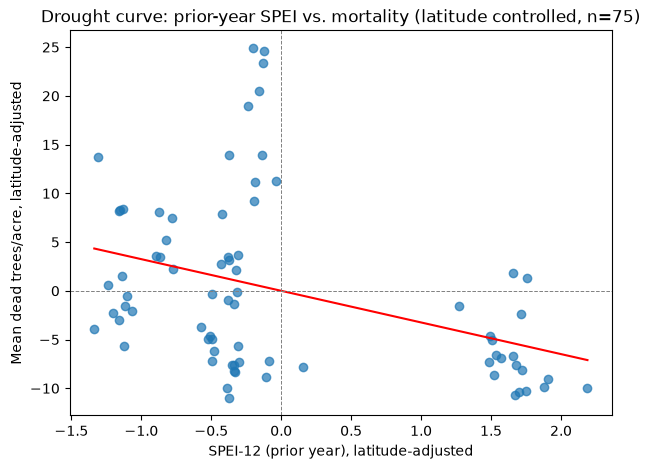

In [38]:
# residualize mean_tpa against latitude only
lat_X = sm.add_constant(panel[["lat", "lat_sq"]])
resid_tpa = sm.OLS(panel["mean_tpa"], lat_X).fit().resid

# residualize spei_lag1 against latitude only (same covariates)
resid_spei = sm.OLS(panel["spei_lag1"], lat_X).fit().resid

plt.figure(figsize=(7,5))
plt.scatter(resid_spei, resid_tpa, alpha=0.7)
slope, intercept = np.polyfit(resid_spei, resid_tpa, 1)
xs = np.linspace(resid_spei.min(), resid_spei.max(), 50)
plt.plot(xs, slope*xs + intercept, color="red")
plt.xlabel("SPEI-12 (prior year), latitude-adjusted")
plt.ylabel("Mean dead trees/acre, latitude-adjusted")
plt.title("Drought curve: prior-year SPEI vs. mortality (latitude controlled, n=75)")
plt.axhline(0, color="grey", linestyle="--", linewidth=0.7)
plt.axvline(0, color="grey", linestyle="--", linewidth=0.7)
plt.savefig("../data/raw/drought_partial_regression_lag1.png", dpi=150)
plt.show()
